# Problem
Recover sharper red and blue scene intensities from a real photograph made with a diffractive lens. Wavelength-dependent blur varies across the image. The simultaneously measured green channel provides structural guidance, but is neither a restored image nor ground truth.

In [1]:
from pathlib import Path
import os,sys,time,numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').exists():ROOT=ROOT.parent
os.chdir(ROOT);sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.visualization import *
image=load_data()
original=np.load('notebooks/reference_outputs/upstream.npz',allow_pickle=False)['reconstruction'][0]

## Data
The complete1585by886 author-supplied real photograph is used, without synthetic degradation or a smaller benchmark crop. Intensities are decoded digital values, not calibrated radiance. There is no independent sharp GT. The separately supplied blind-deconvolved green image is an archived algorithm result; it is deliberately not treated as an observed input. The selected original branch is use_blind=0.

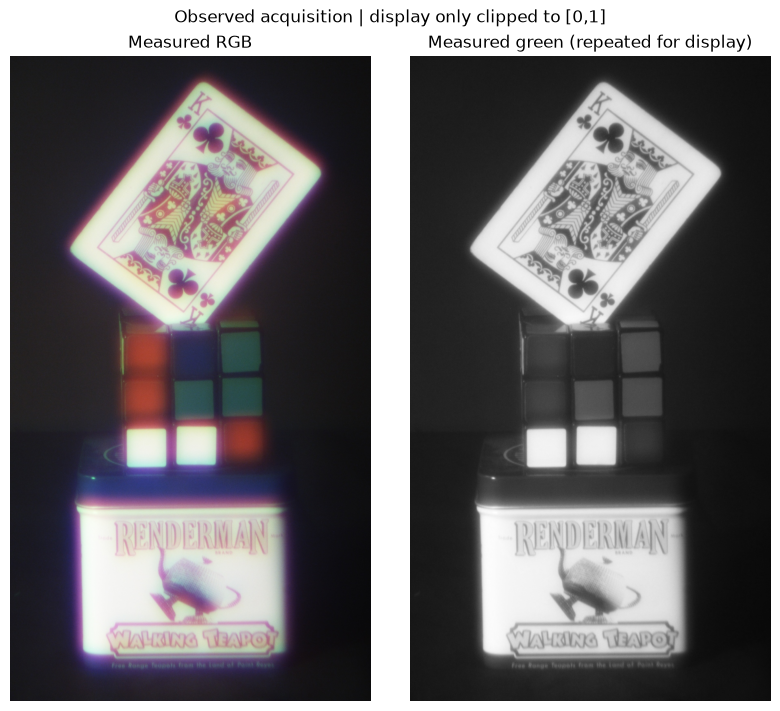

In [2]:
image_comparison({'Measured RGB':image,'Measured green (repeated for display)':np.repeat(image[:,:,1,None],3,axis=2)},'Observed acquisition');plt.show()

## Physics

For patch p and channel c, the model is $y_{pc}=h_{pc}*x_{pc}+n_{pc}$. Here y is observed intensity, x the sharper unknown, h the unknown local blur, n model/noise error and the star periodic patch convolution. Local kernels and scene colors are jointly ambiguous. Overlap and cross-channel structure constrain that ambiguity without asserting identical RGB reflectance.

## Method

For Fourier transforms X of the current estimate and Y of observed color, update

$$H=\frac{\overline X Y}{\overline X X+\beta+\alpha(|D_x|^2+|D_y|^2)}.$$

Dx and Dy are Fourier transforms of forward-difference filters; alpha=beta=.3. Apply H to green to synthesize a matched-blur guide. Fit four local coefficients for constant, guide intensity and x/y derivatives, then evaluate those coefficients on the less-blurred measured green. Hamming-weighted overlap joins patches. PSF patches are500pixels/stride100; transfer patches60/stride12. Three exact alternating iterations are used. No positivity or kernel normalization is added.


Fresh full-image seconds 14.709928399999626
Full signed NCC / range NRMSE against original: (1.000000000000003, 5.596866888793672e-13)
Signed range: -0.1313454703536196 1.1918888897881428


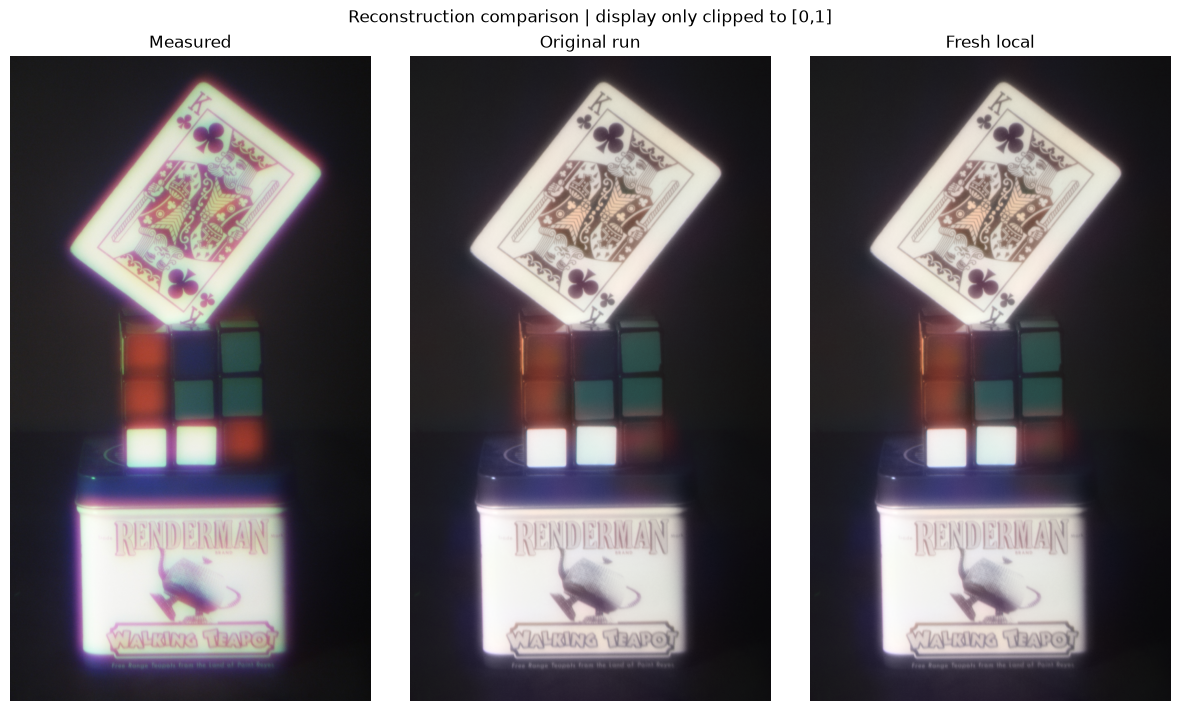

In [3]:
tick=time.perf_counter()
result,details=reconstruct(image,capture=True)
print('Fresh full-image seconds',time.perf_counter()-tick)
print('Full signed NCC / range NRMSE against original:',metrics(result[0],original))
print('Signed range:',result.min(),result.max())
image_comparison({'Measured':image,'Original run':original,'Fresh local':result[0]},'Reconstruction comparison');plt.show()

## Results
Both original and fresh images reconstruct the same full observations. Their agreement validates extraction, not unknown scene accuracy. The following fixed zoom regions are only visualization crops; every benchmark pixel is reconstructed and evaluated. Display clipping is explicitly separate from the signed saved numerical arrays.

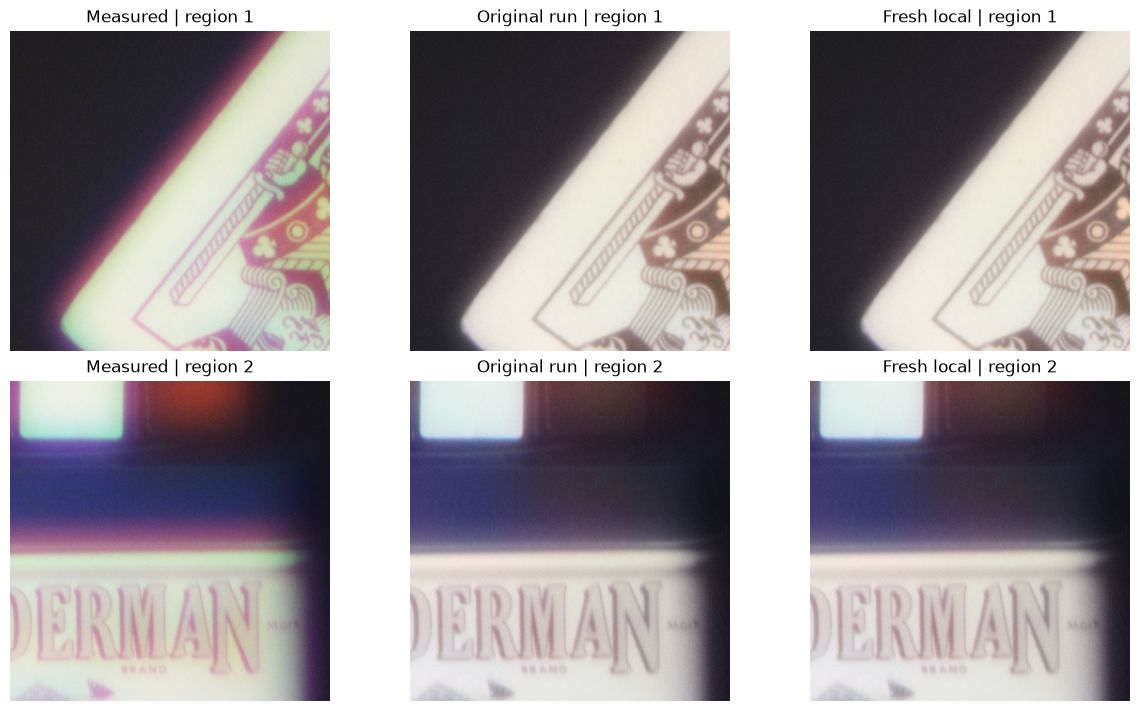

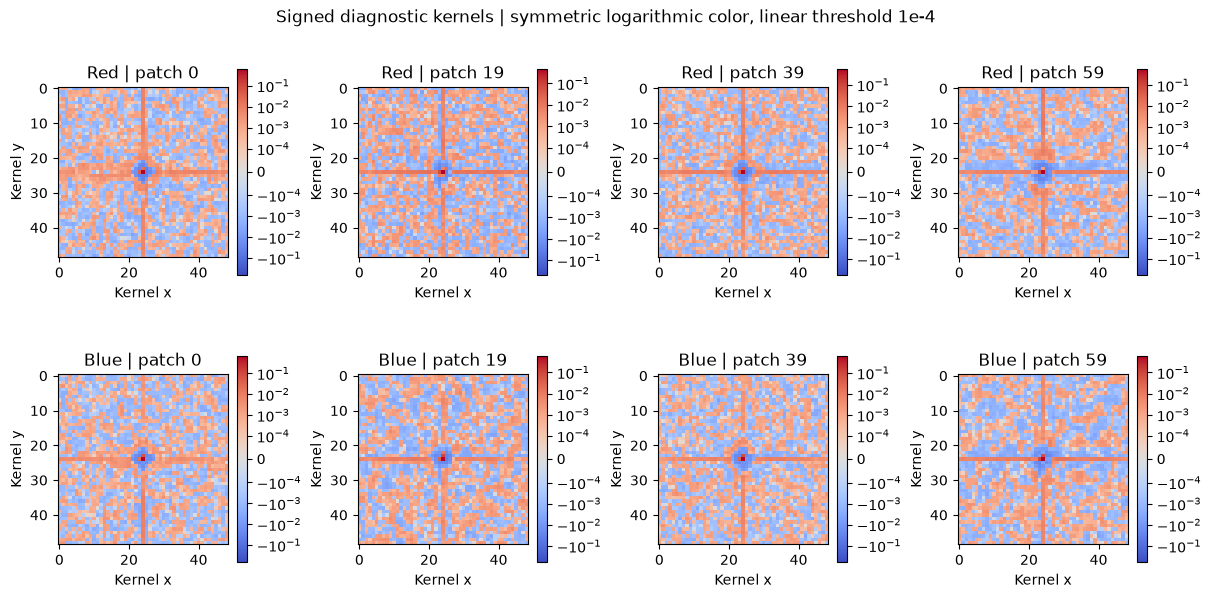

In [4]:
zoom_comparison({'Measured':image,'Original run':original,'Fresh local':result[0]});plt.show()
psf_figure(details);plt.show()

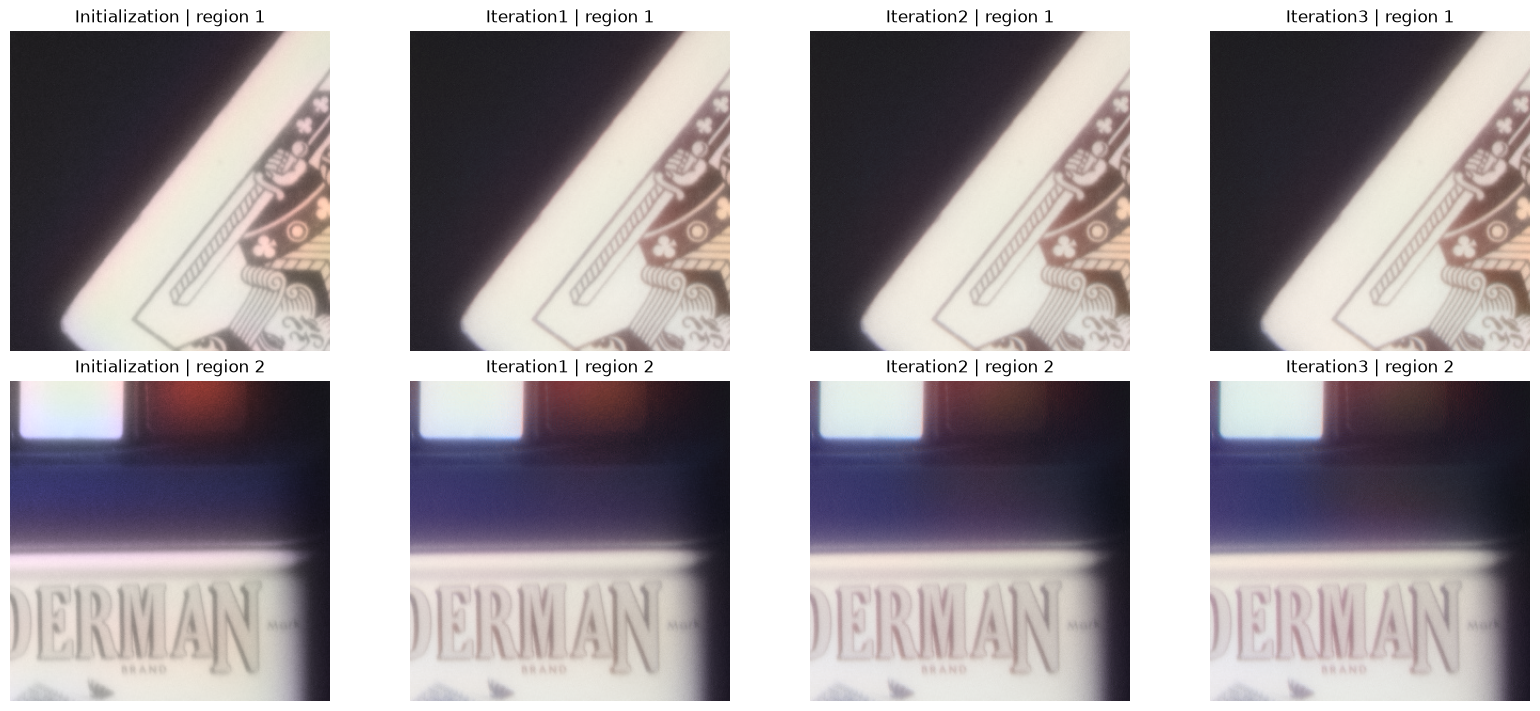

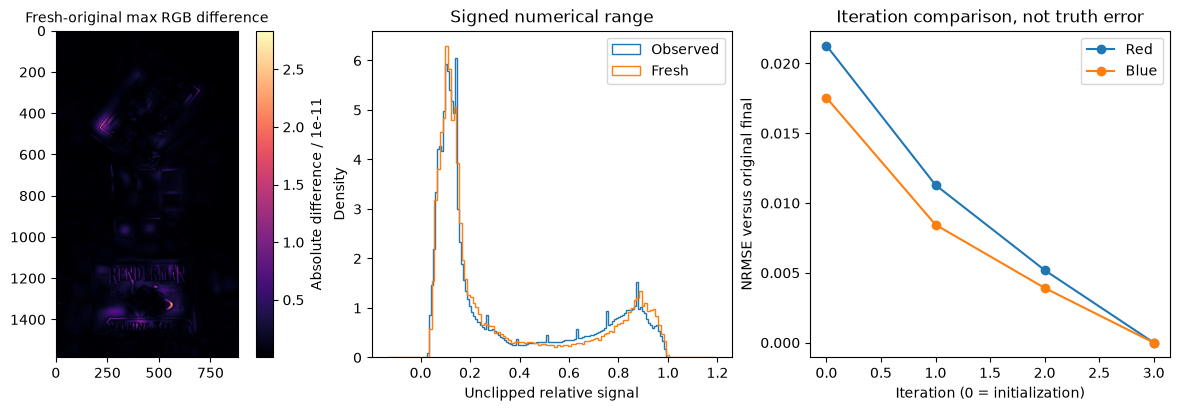

In [5]:
initial=image.copy();iterations=[]
for c in (0,2):initial[:,:,c]=details[c]['initial']
for k in range(3):
    a=image.copy()
    for c in (0,2):a[:,:,c]=details[c]['iteration'][k]['deblur']
    iterations.append(a)
zoom_comparison({'Initialization':initial,**{f'Iteration{k+1}':a for k,a in enumerate(iterations)}});plt.show()
diagnostics(result[0],original,image,details);plt.show()

### Parameter sensitivity
These full-image reconstructions change regularization strength or transfer window, holding the observations fixed. Their difference from the primary method is not truth error. The cropped diagnostic kernels are not substituted for the full Fourier kernels used during inversion. The optional original blind-green branch would introduce a different computed guide and is outside this measured-guidance binding.

Half regularization seconds 20.978636200074106 agreement with primary (0.9999986255612744, 0.0005731978876663493)


Double regularization seconds 24.950770600000396 agreement with primary (0.999997359893391, 0.0007944139258192087)


Window 50 seconds 26.75931779993698 agreement with primary (0.9998822347891596, 0.00531697701743414)


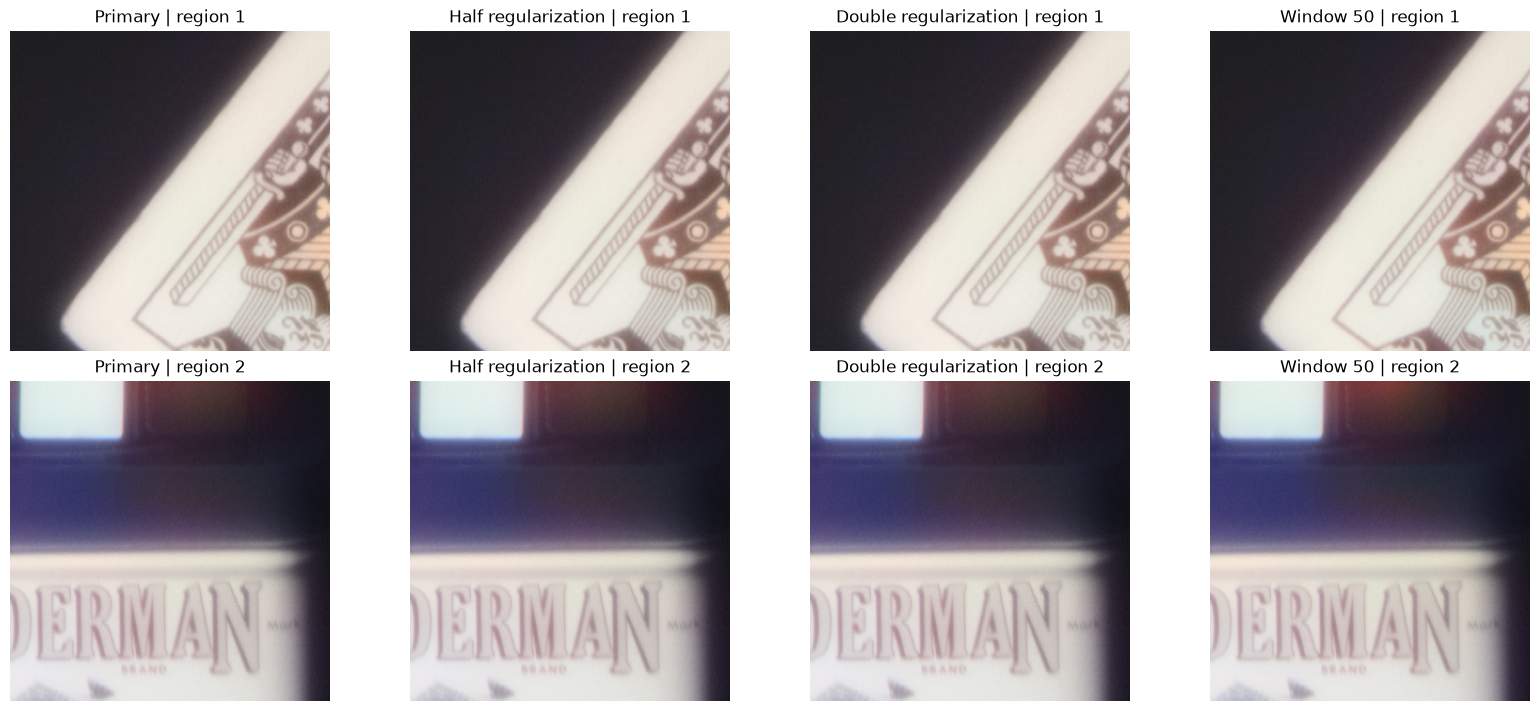

In [6]:
variants={'Primary':result[0]}
for name,kw in [('Half regularization',dict(alpha=.15,beta=.15)),('Double regularization',dict(alpha=.6,beta=.6)),('Window 50',dict(transfer_size=50))]:
    tick=time.perf_counter();variants[name]=reconstruct(image,**kw)[0][0];print(name,'seconds',time.perf_counter()-tick,'agreement with primary',metrics(variants[name],result[0]))
zoom_comparison(variants);plt.show()

## Conclusion
Cross-channel structure restores color detail while preserving the measured green image. Independent original/local numerical agreement and operator checks validate the extraction. Unknown sharp ground truth, channel-specific texture, uncalibrated digital radiometry and signed overshoot limit physical claims. Parameter changes can alter recovered color detail, so visual sharpness alone is not evidence of accuracy.